In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

!rm -rf codsoft-projects
!git clone https://github.com/Priyadh1/codsoft-projects.git

df = pd.read_excel("codsoft-projects/Task3_Sales_Prediction/CodSoft_Sales_Prediction_Dataset.xlsx")

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
df.head()

Cloning into 'codsoft-projects'...
remote: Enumerating objects: 91, done.
remote: Counting objects: 100% (91/91), done.
remote: Compressing objects: 100% (84/84), done.
remote: Total 91 (delta 24), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (91/91), 1.16 MiB | 8.03 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Shape: (200, 4)
Missing values: 0 | Duplicates: 0


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


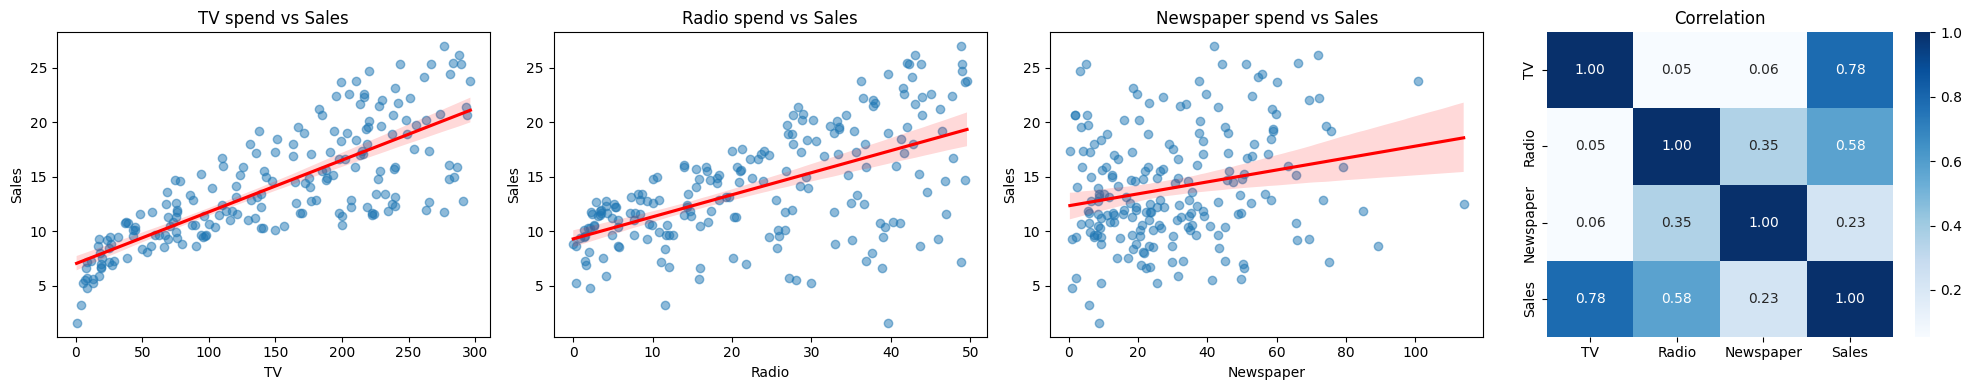

TV         alone explains 61% of the change in Sales
Radio      alone explains 33% of the change in Sales
Newspaper  alone explains 5% of the change in Sales
All three  together explain 90%


In [4]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))

for i, col in enumerate(["TV", "Radio", "Newspaper"]):
    sns.regplot(data=df, x=col, y="Sales", ax=ax[i],
                scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
    ax[i].set_title(f"{col} spend vs Sales")

sns.heatmap(df.corr(), annot=True, cmap="Blues", fmt=".2f", ax=ax[3])
ax[3].set_title("Correlation")

plt.tight_layout()
plt.show()

# How much does each channel explain on its own?
from sklearn.linear_model import LinearRegression

for col in ["TV", "Radio", "Newspaper"]:
    r2 = LinearRegression().fit(df[[col]], df["Sales"]).score(df[[col]], df["Sales"])
    print(f"{col:10s} alone explains {r2*100:.0f}% of the change in Sales")

features = ["TV", "Radio", "Newspaper"]
r2_all = LinearRegression().fit(df[features], df["Sales"]).score(df[features], df["Sales"])
print(f"{'All three':10s} together explain {r2_all*100:.0f}%")

In [5]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = ["TV", "Radio", "Newspaper"]
X, y = df[features], df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

setups = {
    "Linear: TV only (reference notebook)": (LinearRegression(), ["TV"]),
    "Linear: TV + Radio": (LinearRegression(), ["TV", "Radio"]),
    "Linear: all 3 channels": (LinearRegression(), features),
    "Random Forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42), features),
    "Gradient Boosting": (GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=42), features),
}

rows = []
for name, (model, cols) in setups.items():
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    cv = cross_val_score(model, X[cols], y, cv=5, scoring="r2").mean()
    rows.append([name,
                 round(mean_absolute_error(y_test, pred), 2),
                 round(np.sqrt(mean_squared_error(y_test, pred)), 2),
                 round(r2_score(y_test, pred), 3),
                 round(cv, 3),
                 round(r2_score(y_train, model.predict(X_train[cols])), 3)])

res = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE", "Test R2", "5-Fold CV R2", "Train R2"])
print(res.to_string(index=False))

                               Model  MAE  RMSE  Test R2  5-Fold CV R2  Train R2
Linear: TV only (reference notebook) 2.44  3.19    0.677         0.593     0.591
                  Linear: TV + Radio 1.44  1.77    0.901         0.889     0.896
              Linear: all 3 channels 1.46  1.78    0.899         0.887     0.896
                       Random Forest 0.66  0.79    0.980         0.974     0.993
                   Gradient Boosting 0.66  0.77    0.981         0.972     0.995


In [7]:
import ipywidgets as widgets
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor

feats = ["TV", "Radio", "Newspaper"]
sim_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=42).fit(df[feats], df["Sales"])
sim_low = GradientBoostingRegressor(loss="quantile", alpha=0.1, n_estimators=150, learning_rate=0.05, max_depth=2, random_state=42).fit(df[feats], df["Sales"])
sim_high = GradientBoostingRegressor(loss="quantile", alpha=0.9, n_estimators=150, learning_rate=0.05, max_depth=2, random_state=42).fit(df[feats], df["Sales"])
maxes = {"TV": float(df["TV"].max()), "Radio": float(df["Radio"].max()), "Newspaper": float(df["Newspaper"].max())}
colors = {"TV": "#6e1b2a", "Radio": "#c9a34e", "Newspaper": "#7f8c8d"}

def predict_sales(tv, radio, news):
    p = pd.DataFrame([[tv, radio, news]], columns=feats)
    s = float(sim_model.predict(p)[0])
    lo, hi = float(sim_low.predict(p)[0]), float(sim_high.predict(p)[0])
    return s, min(lo, s), max(hi, s)

def simulate(tv, radio, news):
    s, lo, hi = predict_sales(tv, radio, news)
    cur = {"TV": tv, "Radio": radio, "Newspaper": news}

    # Where should the NEXT 10 (thousand dollars) go?
    gains = {}
    for ch in feats:
        more = dict(cur); more[ch] = min(cur[ch] + 10, maxes[ch])
        gains[ch] = predict_sales(more["TV"], more["Radio"], more["Newspaper"])[0] - s

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1.6, 1]})

    # Panel 1: predicted sales with likely range
    ax[0].bar(["Predicted\nsales"], [s], color="#2e7d32", width=0.5)
    ax[0].errorbar([0], [s], yerr=[[s - lo], [hi - s]], color="black", capsize=10, lw=2)
    ax[0].set_ylim(0, 32)
    ax[0].set_title(f"Predicted sales: {s:.1f}\n(likely {lo:.1f} to {hi:.1f})")

    # Panel 2: response curves (vary one channel, keep the others fixed)
    for ch in feats:
        xs = np.linspace(0, maxes[ch], 40)
        ys = []
        for x in xs:
            d = dict(cur); d[ch] = x
            ys.append(predict_sales(d["TV"], d["Radio"], d["Newspaper"])[0])
        ax[1].plot(xs / maxes[ch] * 100, ys, label=ch, color=colors[ch], lw=2.5)
        ax[1].scatter([cur[ch] / maxes[ch] * 100], [s], color=colors[ch], s=70, zorder=5, edgecolor="black")
    ax[1].set_xlabel("Spend on that channel (% of the highest spend in the data)")
    ax[1].set_ylabel("Predicted sales")
    ax[1].set_title("What if you spend more or less on ONE channel?")
    ax[1].legend()

    # Panel 3: where should the next 10 go?
    best = max(gains, key=gains.get)
    ax[2].bar(list(gains), [gains[k] for k in gains], color=[colors[k] for k in gains])
    ax[2].axhline(0, color="black", lw=0.8)
    ax[2].set_title("Extra sales from +10 on a channel")
    plt.tight_layout()
    plt.show()

    print(f"Spending now: TV {tv:.0f} | Radio {radio:.0f} | Newspaper {news:.0f}  (total {tv + radio + news:.0f} thousand dollars)")
    print(f"Best place for the next 10 thousand dollars: {best}  (+{gains[best]:.2f} sales)")

sty = {"description_width": "90px"}
sl = lambda name, v, mx: widgets.FloatSlider(value=v, min=0, max=mx, step=5, description=name, style=sty,
                                           layout=widgets.Layout(width="520px"), continuous_update=False)
tv_w, radio_w, news_w = sl("TV", 150, maxes["TV"]), sl("Radio", 25, maxes["Radio"]), sl("Newspaper", 30, maxes["Newspaper"])
out = widgets.interactive_output(simulate, {"tv": tv_w, "radio": radio_w, "news": news_w})
display(widgets.VBox([widgets.HTML("<h3>📈 Sales Simulator: move the sliders (budgets in thousand dollars)</h3>"),
                      tv_w, radio_w, news_w, out]))